<a href="https://colab.research.google.com/github/DTH235740-NGUYENTHIYENPHUONG/DoAnNhom_TTNT/blob/main/Phantichbenhtrenlaxoai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!rm -rf /content/mango_dataset
!cp -r "/content/drive/MyDrive/mango_dataset" /content/

Mounted at /content/drive


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# Đường dẫn tới thư mục chứa ảnh trên Google Drive
DATA_DIR = '/content/mango_dataset'
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Load dữ liệu huấn luyện (80%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Load dữ liệu kiểm thử (20%)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print("Danh sách 4 lớp bệnh:", class_names)

# Tối ưu bộ nhớ đệm
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 2000 files belonging to 4 classes.
Using 1600 files for training.
Found 2000 files belonging to 4 classes.
Using 400 files for validation.
Danh sách 4 lớp bệnh: ['Anthracnose', 'Die Back', 'Healthy', 'Powdery Mildew']


In [ ]:
from tensorflow.keras import layers, models

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),
    layers.RandomZoom(height_factor=(-0.25, 0.2)), # Phóng to mô phỏng ảnh chụp cận cảnh
    layers.RandomContrast(0.2),                    # Học phân biệt độ tương phản phấn trắng - lá xanh
    layers.RandomBrightness(0.2),
])

# Tải mô hình gốc MobileNetV2 đã huấn luyện sẵn
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False # Đóng đóng băng trọng số

# Thiết lập lớp phân loại cho 4 bệnh
inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
from google.colab import files

# Giai đoạn 1: Huấn luyện 15 epochs đầu (đóng băng base_model)
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

# Giai đoạn 2: Mở khóa 30 lớp cuối của MobileNetV2 để học chi tiết vết nấm phấn trắng
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), # Tốc độ học nhỏ để tránh làm hỏng trọng số
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    '/content/drive/MyDrive/mobilenetv2_mango_final.keras',
    save_best_only=True,
    monitor='val_accuracy'
)

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[checkpoint_cb]
)

# Gộp lịch sử huấn luyện để Ô 5 vẽ biểu đồ không bị lỗi
history = history2
for k in history.history:
    history.history[k] = history1.history[k] + history2.history[k]

# Tải file mô hình mới về máy tính
files.download('/content/drive/MyDrive/mobilenetv2_mango_final.keras')

Epoch 1/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 144ms/step - accuracy: 0.7875 - loss: 0.5595 - val_accuracy: 0.9925 - val_loss: 0.0909
Epoch 2/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.9837 - loss: 0.0927 - val_accuracy: 0.9950 - val_loss: 0.0447
Epoch 3/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.9906 - loss: 0.0570 - val_accuracy: 0.9950 - val_loss: 0.0286
Epoch 4/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.9931 - loss: 0.0416 - val_accuracy: 0.9975 - val_loss: 0.0195
Epoch 5/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.9956 - loss: 0.0333 - val_accuracy: 0.9975 - val_loss: 0.0164
Epoch 6/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy: 0.9969 - loss: 0.0251 - val_accuracy: 0.9975 - val_loss: 0.0147
Epoch 7/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - accuracy: 0.9981 - loss: 0.0214 - val_accuracy: 1.0000 - val_loss: 0.0117
Epoch 8/15
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - accuracy: 0.9937 - loss: 0.0290 - val_accuracy: 1.0000 -

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

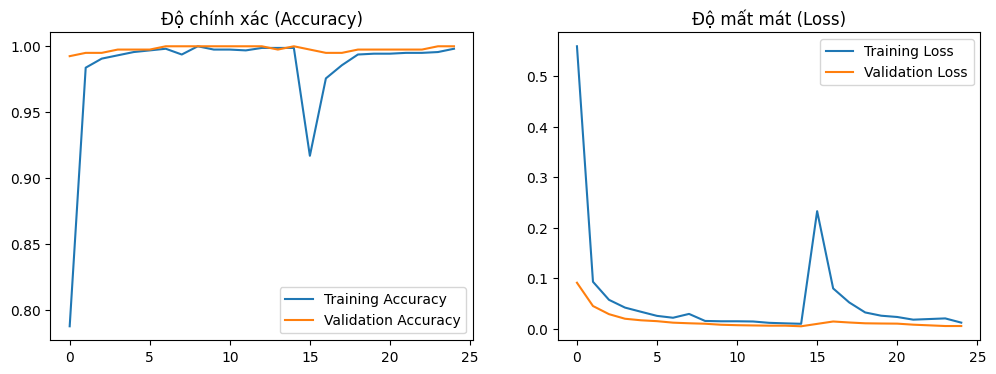

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Độ chính xác (Accuracy)')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Độ mất mát (Loss)')
plt.show()

In [ ]:
from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array

uploaded = files.upload()

for filename in uploaded.keys():
    img_path = filename
    img = load_img(img_path, target_size=(224, 224))
    img_array = img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = 100 * np.max(predictions[0])

    print(f"\n---> Kết quả:")
    print(f"File ảnh: {filename}")
    print(f"Dự đoán lớp bệnh: {predicted_class}")
    print(f"Độ tin cậy: {confidence:.2f}%")

Saving nhan-biet-benh-phan-trang-o-cay-xoai.jpg to nhan-biet-benh-phan-trang-o-cay-xoai.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step

---> Kết quả:
File ảnh: nhan-biet-benh-phan-trang-o-cay-xoai.jpg
Dự đoán lớp bệnh: Powdery Mildew
Độ tin cậy: 92.76%


                precision    recall  f1-score   support

   Anthracnose       1.00      1.00      1.00       104
      Die Back       1.00      1.00      1.00       100
       Healthy       1.00      1.00      1.00       102
Powdery Mildew       1.00      1.00      1.00        94

      accuracy                           1.00       400
     macro avg       1.00      1.00      1.00       400
  weighted avg       1.00      1.00      1.00       400



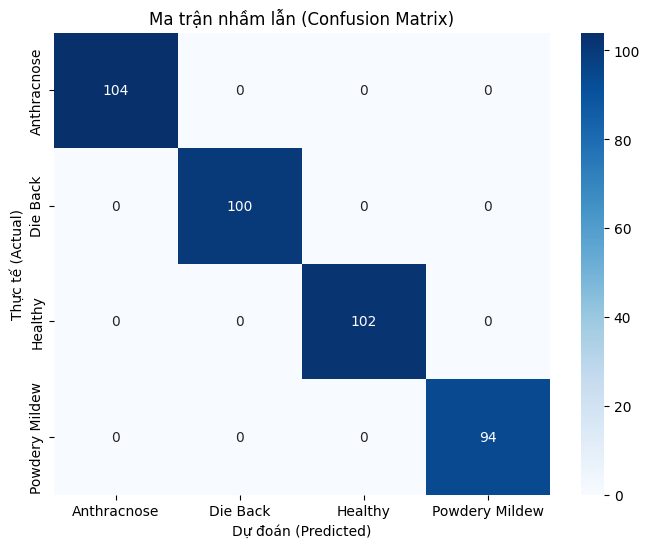

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Lấy nhãn thực tế và nhãn dự đoán trên tập Validation
y_pred = []
y_true = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

# In báo cáo chi tiết Precision, Recall, F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))

# Vẽ đồ thị Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.xlabel('Dự đoán (Predicted)')
plt.ylabel('Thực tế (Actual)')
plt.title('Ma trận nhầm lẫn (Confusion Matrix)')
plt.show()

Các lớp mô hình đang học: ['Anthracnose', 'Die Back', 'Healthy', 'Powdery Mildew']
- Anthracnose: 78.51%
- Die Back: 5.23%
- Healthy: 9.28%
- Powdery Mildew: 6.98%


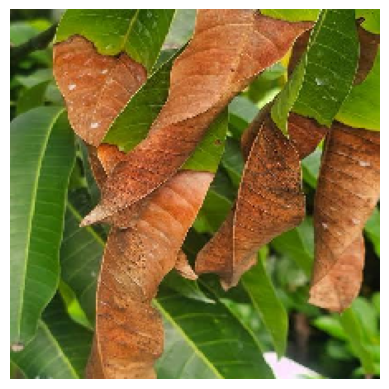

In [ ]:
print("Các lớp mô hình đang học:", class_names)
for name, prob in zip(class_names, predictions[0]):
    print(f"- {name}: {prob*100:.2f}%")

plt.imshow(img)
plt.axis('off')
plt.show()